<center><h1>Bhatt_Om_HW3</h1></center>
<br>
<br>

Name: Om Bhatt
<br>
Github Username: OmBhatt18
<br>
USC ID: 7536194801

## 1. Time Series Classification Part 1: Feature Creation/Extraction

**Data.** AReM (Activity Recognition system based on Multisensor data fusion), UCI Machine Learning Repository. Sensors on the chest and both ankles recorded a person performing 7 activities: `bending1`, `bending2`, `cycling`, `lying`, `sitting`, `standing`, `walking`. Each `datasetN.csv` file is one instance: a 2-minute recording with 6 time series of 480 values each (`avg_rss12, var_rss12, avg_rss13, var_rss13, avg_rss23, var_rss23`, the mean and variance of the received signal strength between each pair of sensors). There are 88 instances in total.

The 7 activity folders are in `data/AReM/` (`DATA_DIR`), and the CSV outputs are saved to `output/` (`OUT_DIR`).

In [1]:
import os, re, glob
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

pd.set_option('display.max_columns', 50)
pd.set_option('display.width', 200)

DATA_DIR = '../data/AReM'
OUT_DIR = '../output'
ACTIVITIES = ['bending1','bending2','cycling','lying','sitting','standing','walking']
SERIES = ['avg_rss12', 'var_rss12', 'avg_rss13', 'var_rss13', 'avg_rss23', 'var_rss23']
SEED = 42

missing = [a for a in ACTIVITIES if not os.path.isdir(os.path.join(DATA_DIR, a))]
if missing: print("can't find:", missing)

### 1(a) Load the data

Each file starts with a few `#` header lines, followed by `time` and the 6 series. A few files need minor cleaning: one uses a different delimiter, some have stray characters at the end of a line, and one doesn't have exactly 480 rows. `load_instance()` handles all of these without editing the files by hand.

In [2]:
def load_instance(path):
    rows = []
    f = open(path)
    for line in f:
        line = line.strip()
        if line == '' or line[0] == '#':
            continue

        # some files use spaces instead of commas and some have an extra comma at the end
        # so split on both and throw away the empty strings
        vals = [v for v in re.split(r'[,\s]+', line) if v != '']
        if len(vals) < 7:
            continue  # broken line

        rows.append(
            [float(v) for v in vals[:7]]
        )
    f.close()
    return pd.DataFrame(rows, columns=['time'] + SERIES)

In [3]:
def get_num(fname):
    return int(re.search(r'dataset(\d+)\.csv$', fname).group(1))

instances = []
for act in ACTIVITIES:
    files = glob.glob(os.path.join(DATA_DIR, act, 'dataset*.csv'))
    files = sorted(files, key=get_num)   # need numeric sort, otherwise dataset10 < dataset2
    for fn in files:
        instances.append({'activity': act,
                          'file': get_num(fn),
                          'data': load_instance(fn)
        })

print(len(instances))
print(pd.Series([d['activity'] for d in instances]).value_counts().reindex(ACTIVITIES))

88
bending1     7
bending2     6
cycling     15
lying       15
sitting     15
standing    15
walking     15
Name: count, dtype: int64


In [4]:
# files that don't have exactly 480 rows
odd = [(d['activity'], d['file'], len(d['data'])) for d in instances if len(d['data']) != 480]
print('Files without exactly 480 rows:', odd)

Files without exactly 480 rows: [('sitting', 8, 479)]


**Data cleaning notes:**

> * `bending2/dataset4.csv` uses spaces instead of commas.
> * `cycling/dataset9.csv` and `cycling/dataset14.csv` have an extra comma at the end of the last line, which would create an empty 8th column.
> * `sitting/dataset8.csv` has 479 rows instead of 480 (one timestamp is missing).
>
> The loader splits on commas and whitespace together and drops empty strings, so the first three files load correctly without editing them. The missing row in `sitting/dataset8` doesn't matter here: every feature is a summary statistic (min, mean, quartiles, ...), and one missing value out of 480 barely changes any of them, so I didn't impute it.

### 1(b) Train / test split

* **Test:** datasets 1 and 2 in `bending1` and `bending2`, plus datasets 1, 2 and 3 in every other folder.
* **Train:** everything else (69 train / 19 test).

In [5]:
def is_test(activity, n):
    if activity in ('bending1', 'bending2'):
        return n <= 2
    return n <= 3

for d in instances:
    if is_test(d['activity'], d['file']):
        d['split'] = 'test'
    else:
        d['split'] = 'train'

In [6]:
split_counts = pd.crosstab(pd.Series([d['activity'] for d in instances], name='activity'),
                           pd.Series([d['split'] for d in instances], name='split'))
split_counts.loc['Total'] = split_counts.sum()
split_counts

split,test,train
activity,,
bending1,2,5
bending2,2,4
cycling,3,12
lying,3,12
sitting,3,12
standing,3,12
walking,3,12
Total,19,69


### 1(c) Feature extraction

#### 1(c)i Time-domain features commonly used in time series classification

Time-domain features are computed directly from the signal values over time, as opposed to frequency-domain features such as FFT coefficients. Commonly used ones:

| Category | Features |
|---|---|
| Central tendency | mean, median, mode, trimmed mean, root mean square (RMS) |
| Extremes | minimum, maximum, range (max − min), peak-to-peak amplitude |
| Spread | variance, standard deviation, interquartile range, mean absolute deviation, coefficient of variation |
| Order statistics | 1st quartile, 3rd quartile, other percentiles (5th, 95th, ...) |
| Distribution shape | skewness, kurtosis |
| Energy / magnitude | signal energy (sum of squares), sum of absolute values, signal magnitude area |
| Temporal structure | autocorrelation at different lags, zero-crossing / mean-crossing rate, number of peaks, slope of a linear trend, mean of first differences |
| Complexity | sample / approximate entropy, Hjorth parameters (activity, mobility, complexity) |

#### 1(c)ii Extract min, max, mean, median, std, 1st and 3rd quartile

For each of the 6 series in every instance: `min, max, mean, median, std, 1st_quart, 3rd_quart`. That gives 7 × 6 = **42 features per instance**, named `<stat><series number>` (e.g. `mean1`, `3rd_quart6`).

Standard deviation is the sample std (`ddof=1`). Features are kept on their raw scale; standardization can be done later, before modelling.

In [7]:
STATS = ['min', 'max', 'mean', 'median', 'std', '1st_quart', '3rd_quart']

# keeping raw values, not standardizing (can do that later before the model)
def extract_features(df):
    feats = {}
    i = 1
    for col in SERIES:
        s = df[col]
        feats['min'+str(i)] = s.min()
        feats['max'+str(i)] = s.max()
        feats['mean'+str(i)] = s.mean()
        feats['median'+str(i)] = s.median()
        feats['std'+str(i)] = s.std()   # pandas std is ddof=1 by default
        feats['1st_quart'+str(i)] = s.quantile(.25)
        feats['3rd_quart'+str(i)] = s.quantile(.75)
        i += 1
    return feats

In [8]:
rows = []
for d in instances:
    r = {'activity': d['activity'], 'file': d['file'], 'split': d['split']}
    r.update(extract_features(d['data']))
    rows.append(r)

features = pd.DataFrame(rows)
features.index = np.arange(1, len(features)+1)
features.index.name = 'Instance'
FEATURE_COLS = [s + str(k) for k in range(1, 7) for s in STATS]

features.to_csv(os.path.join(OUT_DIR, 'arem_time_domain_features.csv'))
features.round(3).head(10)

,activity,file,split,min1,max1,mean1,median1,std1,1st_quart1,3rd_quart1,min2,max2,mean2,median2,std2,1st_quart2,3rd_quart2,min3,max3,mean3,median3,std3,1st_quart3,3rd_quart3,min4,max4,mean4,median4,std4,1st_quart4,3rd_quart4,min5,max5,mean5,median5,std5,1st_quart5,3rd_quart5,min6,max6,mean6,median6,std6,1st_quart6,3rd_quart6
Instance,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
1,bending1,1,test,37.25,45.00,40.625,40.50,1.477,39.250,42.00,0.0,1.30,0.359,0.43,0.323,0.00,0.500,4.00,29.50,19.041,19.250,4.463,16.00,23.250,0.0,7.23,0.833,0.50,0.966,0.00,1.120,27.25,38.25,34.311,35.000,2.188,33.000,36.00,0.0,1.92,0.571,0.43,0.583,0.00,1.30
2,bending1,2,test,38.00,45.67,42.813,42.50,1.436,42.000,43.67,0.0,1.22,0.372,0.47,0.289,0.00,0.500,2.00,29.50,20.097,21.000,3.894,19.00,22.250,0.0,5.76,0.876,0.50,1.047,0.00,1.145,27.67,38.50,33.025,33.000,1.995,32.000,34.50,0.0,3.11,0.571,0.43,0.601,0.00,1.30
3,bending1,3,train,35.00,47.40,43.954,44.33,1.559,43.000,45.00,0.0,1.70,0.426,0.47,0.339,0.00,0.500,6.50,29.75,22.122,23.000,3.031,19.75,24.000,0.0,4.44,0.497,0.43,0.551,0.00,0.830,29.00,38.50,35.588,36.000,2.000,35.362,36.50,0.0,1.79,0.493,0.43,0.514,0.00,0.94
4,bending1,4,train,33.00,47.75,42.180,43.50,3.671,39.150,45.00,0.0,3.00,0.696,0.50,0.631,0.00,1.120,8.50,30.00,22.184,23.000,3.810,20.50,24.372,0.0,5.15,0.990,0.83,0.954,0.43,1.300,20.00,38.67,33.494,35.000,3.849,30.458,36.33,0.0,2.18,0.614,0.50,0.524,0.00,1.00
5,bending1,5,train,33.00,45.75,41.678,41.75,2.243,41.330,42.75,0.0,2.83,0.536,0.50,0.405,0.43,0.710,3.00,28.25,19.007,19.125,4.087,16.50,22.062,0.0,6.42,0.842,0.50,0.929,0.43,1.120,23.67,37.50,29.857,30.000,2.411,28.458,31.25,0.0,1.79,0.383,0.43,0.389,0.00,0.50
6,bending1,6,train,37.00,48.00,43.455,43.25,1.386,42.500,45.00,0.0,1.58,0.378,0.47,0.316,0.00,0.500,5.75,27.00,15.793,15.000,3.848,13.00,18.270,0.0,10.03,0.849,0.50,0.996,0.43,1.120,8.00,33.50,23.035,23.500,2.489,22.250,24.00,0.0,5.26,0.680,0.50,0.623,0.43,0.87
7,bending1,7,train,36.25,48.00,43.969,44.50,1.618,43.310,44.67,0.0,1.50,0.413,0.47,0.263,0.43,0.500,1.50,26.33,15.868,16.250,3.742,14.25,18.000,0.0,5.17,0.666,0.47,0.789,0.00,0.940,11.33,30.75,22.104,21.670,3.318,20.500,23.75,0.0,2.96,0.555,0.49,0.488,0.00,0.83
8,bending2,1,test,12.75,51.00,24.563,24.25,3.738,23.188,26.50,0.0,6.87,0.591,0.43,0.837,0.00,0.710,0.00,25.33,19.121,20.250,4.300,18.00,22.000,0.0,6.76,0.737,0.47,0.927,0.00,0.870,10.67,30.00,23.493,23.750,3.694,20.500,27.00,0.0,4.97,0.700,0.50,0.694,0.43,0.87
9,bending2,2,test,0.00,42.75,27.465,28.00,3.584,25.500,30.00,0.0,7.76,0.450,0.43,0.767,0.00,0.500,7.50,35.00,20.843,20.750,3.826,18.00,22.500,0.0,5.76,0.780,0.50,0.904,0.00,0.940,0.00,33.00,17.618,18.000,5.054,15.000,20.75,0.0,6.76,1.122,0.83,1.012,0.47,1.30


#### 1(c)iii Standard deviation of each feature and its 90% bootstrap confidence interval

For each of the 42 features:
1. Compute its standard deviation across the 88 instances.
2. Build a 90% percentile bootstrap confidence interval: resample the 88 values with replacement B = 1000 times, compute the std of each resample, and take the 5th and 95th percentiles.

In [9]:
def bootstrap_std_ci(x, B=1000, alpha=0.10, rng=None):
    if rng is None:
        rng = np.random.default_rng()
    x = np.array(x, dtype=float)
    n = len(x)

    # make B rows of n random indexes (with replacement), each row = 1 resample
    # doing it as a matrix is way faster than a for loop over B
    idx = rng.integers(0, n, size=(B, n))
    sds = x[idx].std(axis=1, ddof=1)

    # alpha = 0.1 -> 5th and 95th percentile
    lo = np.percentile(sds, 100*alpha/2)
    hi = np.percentile(sds, 100*(1-alpha/2))
    return lo, hi

rng = np.random.default_rng(SEED)
ci_rows = []
for c in FEATURE_COLS:
    lo, hi = bootstrap_std_ci(features[c], rng=rng)
    ci_rows.append({
        'feature': c, 'std': features[c].std(),
        'CI_90_lower': lo, 'CI_90_upper': hi})

std_ci = pd.DataFrame(ci_rows).set_index('feature')
std_ci.to_csv(os.path.join(OUT_DIR, 'arem_feature_std_bootstrap_ci.csv'))
std_ci.round(4)

,std,CI_90_lower,CI_90_upper
feature,,,
min1,9.5700,8.2096,10.7872
max1,4.3944,3.3346,5.3046
mean1,5.3357,4.6945,5.8481
median1,5.4401,4.7835,6.0017
std1,1.7722,1.5637,1.9515
1st_quart1,6.1536,5.5835,6.6225
3rd_quart1,5.1389,4.3028,5.8666
min2,0.0000,0.0000,0.0000
max2,5.0627,4.6123,5.4064


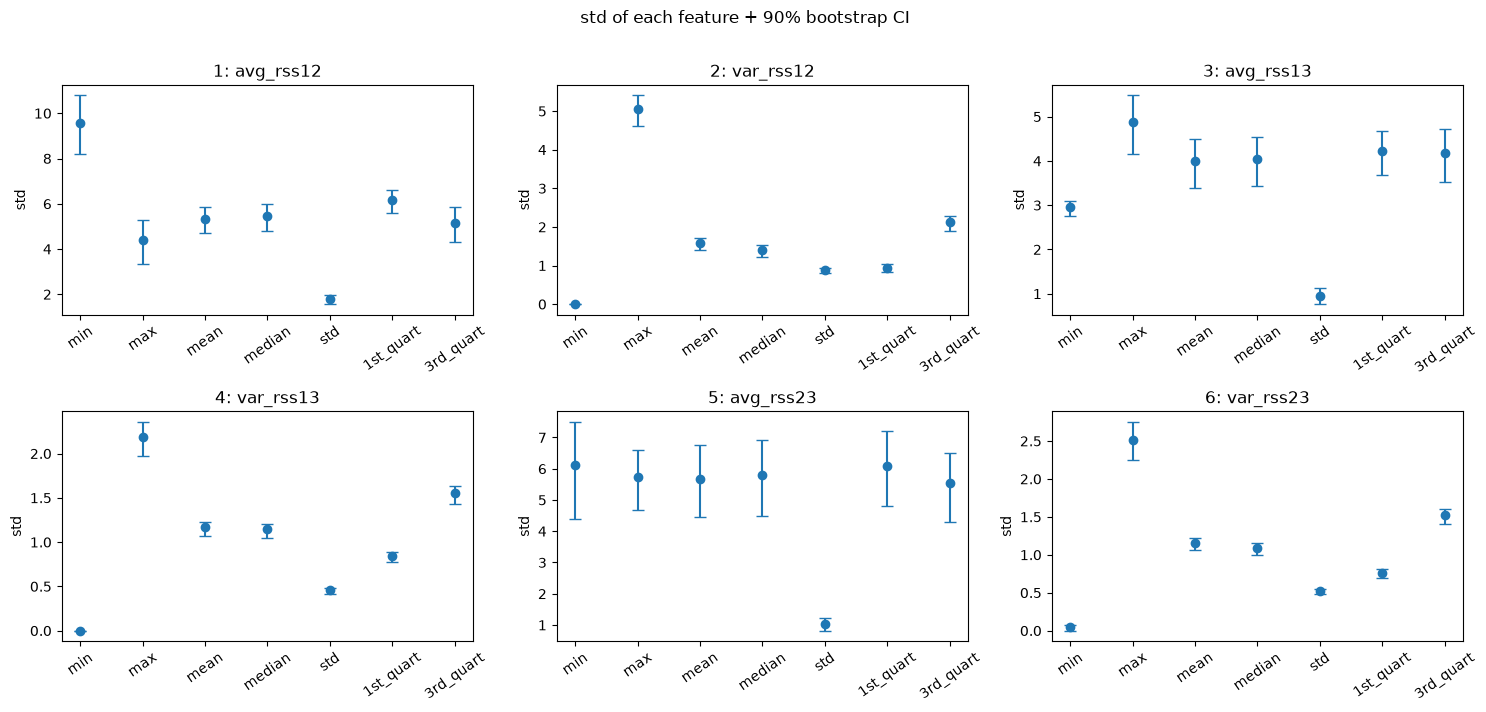

In [10]:
fig, axes = plt.subplots(2, 3, figsize=(15, 7))
k = 1
for ax in axes.ravel():
    sub = std_ci.loc[[s + str(k) for s in STATS]]
    # errorbar needs the distance from the dot, not the bounds themselves
    err = [sub['std'] - sub['CI_90_lower'],
           sub['CI_90_upper'] - sub['std']]
    ax.errorbar(range(7), sub['std'], yerr=err, fmt='o', capsize=4)
    ax.set_xticks(range(7))
    ax.set_xticklabels(STATS, rotation=35)
    ax.set_title(str(k) + ': ' + SERIES[k-1])
    ax.set_ylabel('std')
    k += 1
fig.suptitle('std of each feature + 90% bootstrap CI', y=1.01)
plt.tight_layout()
plt.show()

**Observations:**

> * `min2` and `min4` have a std of exactly 0 and a zero-width interval [0, 0]: the minimum of the var_rss12 and var_rss13 series is 0 in every one of the 88 instances, so these two features carry no information. `min6` is almost the same: it is 0 in 87 of 88 instances, so its interval is tiny and includes 0.
> * The widest intervals belong to series 5 (avg_rss23). For example, the interval for `min5` is about [4.4, 7.5] around 6.1, so the spread of those features across instances is the least certain.
> * The variance series (2, 4, 6) have much smaller and tighter intervals than the average series (1, 3, 5), because their values are on a much smaller scale.

#### 1(c)iv Selecting the three most important time-domain features

The choice is based on three checks, using **training rows only** so the test set doesn't influence it:
* **Separation:** a one-way ANOVA F-statistic per feature, with activity as the group. A high F means the feature separates the activities well.
* **Redundancy:** the average correlation between statistics; nearly duplicate statistics add little.
* **Constant features:** features that never change carry no information.

In [11]:
# only use train rows so the test set doesn't influence what we pick
train = features[features.split == 'train']

const_cols = []
for c in FEATURE_COLS:
    if train[c].nunique() == 1:
        const_cols.append(c)
print('constant:', const_cols)

# ANOVA for each feature, grouped by activity
# high F means the activity means are far apart compared to the spread inside each activity
# -> the feature is good at telling activities apart
res = []
for c in FEATURE_COLS:
    if c in const_cols:
        continue   # f_oneway breaks on constant columns
    grps = []
    for act, g in train.groupby('activity'):
        grps.append(g[c].values)
    F, pval = stats.f_oneway(*grps)
    # 'mean3' -> stat='mean', series=3 (series number is always the last char)
    res.append({'feature': c, 'stat': c[:-1], 'series': int(c[-1]), 'F': F, 'p': pval})

anova = pd.DataFrame(res)
tbl = anova.pivot(index='stat', columns='series', values='F').reindex(STATS)
tbl['median_F'] = tbl.median(axis=1)
tbl.sort_values('median_F', ascending=False).round(1)

constant: ['min2', 'min4']


series,1,2,3,4,5,6,median_F
stat,,,,,,,
mean,15.9,900.2,26.4,651.8,33.4,581.5,307.4
3rd_quart,8.5,807.0,28.1,561.9,32.2,664.8,297.1
median,17.5,477.0,19.4,800.8,28.6,563.1,252.8
1st_quart,21.4,265.5,21.2,244.8,25.5,346.3,135.2
std,9.1,360.9,15.2,128.6,7.8,133.4,71.9
max,1.5,47.7,31.7,29.3,37.0,33.0,32.3
min,11.0,NaN,22.7,NaN,24.1,0.8,16.8


In [12]:
# check if some stats are basically the same thing (e.g. mean vs median)
# correlate stat a with stat b inside each series, then average the 6 numbers
corr = pd.DataFrame(index=STATS, columns=STATS, dtype=float)
for a in STATS:
    for b in STATS:
        tmp = []
        for k in range(1, 7):
            x, y = train[a+str(k)], train[b+str(k)]
            if x.std() > 0 and y.std() > 0:   # min2 and min4 are constant, so their corr is undefined, skip them
                tmp.append(x.corr(y))
        corr.loc[a, b] = np.mean(tmp)

corr.round(2)

,min,max,mean,median,std,1st_quart,3rd_quart
min,1.00,0.36,0.59,0.57,-0.32,0.60,0.52
max,0.36,1.00,0.79,0.75,0.63,0.71,0.82
mean,0.59,0.79,1.00,0.99,0.38,0.98,0.98
median,0.57,0.75,0.99,1.00,0.36,0.98,0.96
std,-0.32,0.63,0.38,0.36,1.00,0.28,0.50
1st_quart,0.60,0.71,0.98,0.98,0.28,1.00,0.93
3rd_quart,0.52,0.82,0.98,0.96,0.50,0.93,1.00


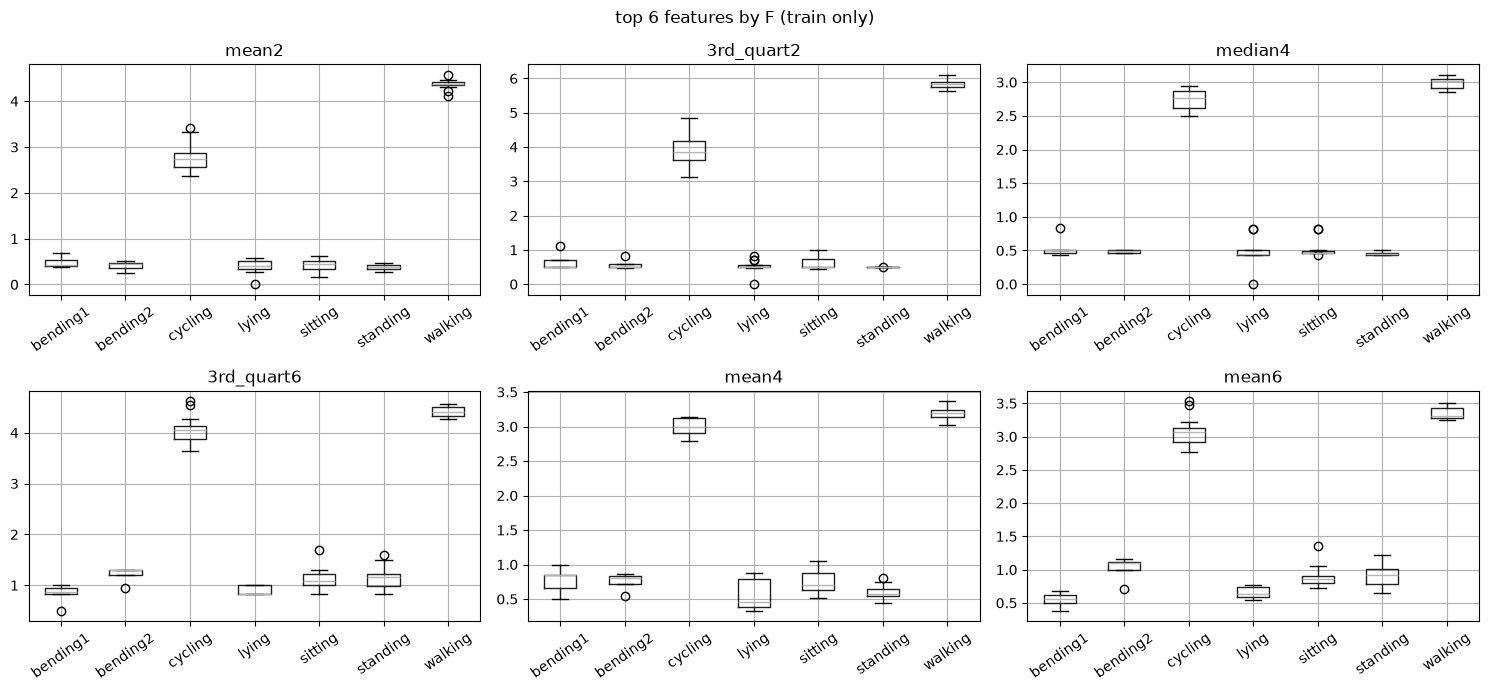

In [13]:
top6 = anova.sort_values('F', ascending=False).feature[:6].tolist()

fig, axes = plt.subplots(2, 3, figsize=(15,7))
for c, ax in zip(top6, axes.ravel()):
    train.boxplot(column=c, by='activity', ax=ax, rot=35)
    ax.set_title(c); ax.set_xlabel('')
fig.suptitle('top 6 features by F (train only)')
plt.tight_layout()
plt.show()

**My three features:** mean, standard deviation and max.

**Why:**
* **Mean** has the highest median F-statistic (≈ 307), so it is the best single statistic for telling the activities apart. Median, 1st quartile and 3rd quartile also score high, but they are correlated with the mean at 0.96–0.99, so they mostly carry the same information. One of that group is enough, and the mean is the strongest.
* **Std** has the highest F outside the mean/median/quartile group (≈ 72, and ≈ 361 on var_rss12), and its correlation with the mean is only ≈ 0.38. So it adds something new: how much the signal fluctuates, which separates moving activities (walking, cycling) from still ones (sitting, lying, standing).
* **Max** has a lower median F, but it is the most discriminative statistic of all on series 3 (avg_rss13, F ≈ 31.7) and series 5 (avg_rss23, F ≈ 37.0). Its correlation with the mean is lower (≈ 0.79) than the quartiles' (≈ 0.98), so it isn't just a repeat of the mean.
* **Min** was not picked: it is constant for `min2` and `min4`, nearly constant for `min6`, and has the lowest median F overall.

(All of this was computed on the training rows only, so the test set didn't influence the choice.)

---
## 2. ISLR 3.7.4

n = 100 observations with one predictor X and a quantitative response Y. Two models are fit:
* a linear regression $Y = \beta_0 + \beta_1 X + \varepsilon$
* a cubic regression $Y = \beta_0 + \beta_1 X + \beta_2 X^2 + \beta_3 X^3 + \varepsilon$

**(a)** Suppose the true relationship is linear. Would you expect the **training** RSS of the cubic model to be lower than, higher than, or the same as that of the linear model, or is there not enough information to tell? Why?

> Lower (or at worst equal). The linear model is a special case of the cubic one (set β2 = β3 = 0), and least squares minimizes the training RSS. So the cubic fit can always match the linear fit on the training data. In practice it will be a bit lower, because the extra terms also fit some of the noise.

**(b)** Same as (a), but for the **test** RSS.

> Higher for the cubic model; the linear model should have the lower test RSS. Since the truth is linear, the linear model already has no bias. The X² and X³ terms only add variance: they fit noise in the training data that doesn't carry over to new data, so the cubic model overfits.

**(c)** Now suppose the true relationship is non-linear, but you don't know how far from linear it is. Same question for the **training** RSS.

> Lower for the cubic model, for the same reason as (a): the models are nested, so the more flexible model always has training RSS lower than or equal to the linear one, regardless of the true relationship.

**(d)** Same as (c), but for the **test** RSS.

> There isn't enough information to tell. If the true relationship is far from linear, the linear model has a lot of bias, and the cubic model should have the lower test RSS. If it is only slightly non-linear, the cubic's reduction in bias is small and its extra variance can outweigh it, so the linear model could have the lower test RSS. It depends on the bias–variance trade-off.